# Lecture 16: every figure in the slides

These cells are the code that produced the latent variables em figures in the deck, with each file write replaced by an inline plot. The notebook runs independently of the slide repository.

In [1]:
# Colab opens this notebook on its own, so fetch the data files that sit
# beside it in the course repository. Running locally, this does nothing.
from pathlib import Path as _Path
import urllib.request as _req
_RAW = 'https://raw.githubusercontent.com/ZhuoranYang/sds265-fall26/main/demos/16-latent-variables-em/'
for _name in ['Auto.csv']:
    if not _Path(_name).exists():
        _req.urlretrieve(_RAW + _name, _name)

In [2]:
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The course palette and figure sizes, copied from slides/figures/sds265_style.py
BLUE, BLUE_BRIGHT, RED, GREEN = '#00356B', '#286DC0', '#7A3E47', '#5B7864'
INK, MUTED, RULE, BLUE_PALE = '#202A35', '#66727E', '#D8E0E8', '#F2F6FA'
BLUE_FILL, RED_FILL, GREEN_FILL = '#8C9FB1', '#B0846F', '#9AAE96'
MORANDI_BLUE, MORANDI_CLAY, MORANDI_SAGE = '#8C9FB1', '#B0846F', '#9AAE96'
MORANDI_MAUVE, MORANDI_SAND, MORANDI_STONE = '#A98FA0', '#C7B392', '#8A8F8A'
MORANDI = [MORANDI_BLUE, MORANDI_CLAY, MORANDI_SAGE, MORANDI_MAUVE, MORANDI_SAND, MORANDI_STONE]
MORANDI_EDGE = {MORANDI_BLUE: '#5C7186', MORANDI_CLAY: '#835747', MORANDI_SAGE: '#6B8067',
                MORANDI_MAUVE: '#7C6373', MORANDI_SAND: '#9A8763', MORANDI_STONE: '#5F645F'}
CYCLE = MORANDI
TEXTWIDTH, TEXTHEIGHT = 5.63, 3.09
FULL, FULL_TALL, FULL_SHORT = (TEXTWIDTH, 2.0), (TEXTWIDTH, 2.35), (TEXTWIDTH, 1.7)
HALF, HALF_TALL = (2.70, 2.05), (2.70, 2.45)

def use_course_style():
    mpl.rcParams.update({'figure.dpi': 130, 'font.size': 9, 'axes.titlecolor': BLUE,
                         'axes.edgecolor': MUTED, 'axes.linewidth': .7,
                         'axes.spines.top': False, 'axes.spines.right': False,
                         'xtick.color': MUTED, 'ytick.color': MUTED,
                         'legend.frameon': False, 'lines.linewidth': 1.8,
                         'axes.prop_cycle': mpl.cycler(color=CYCLE)})

def save(fig, *paths):     # the deck writes files; the notebook shows the plot
    plt.show()
    return Path(paths[0]) if paths else Path('figure.pdf')

use_course_style()
# The deck scripts derive output paths from OUT and NOTES. Nothing is written
# here, so both point at the working directory and the notebook runs anywhere.
OUT = Path('.')
NOTES = Path('.')

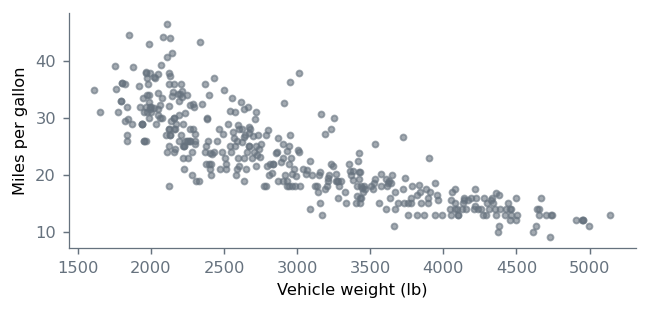

In [3]:
from __future__ import annotations


import matplotlib.colors as mpl_colors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Ellipse
from scipy.special import logsumexp
from scipy.stats import norm
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler



SEED = 26519
COLORS = [BLUE, RED, GREEN, "#8C6D9E", "#C28E4B"]


def log_gaussian(x: np.ndarray, mean: np.ndarray, variance: float) -> np.ndarray:
    dimension = x.shape[1]
    return -.5 * (dimension * np.log(2 * np.pi * variance) + ((x - mean) ** 2).sum(axis=1) / variance)


def em_spherical(x: np.ndarray, k: int, seed: int = 0, steps: int = 60, variance_floor: float = .025):
    rng = np.random.default_rng(seed)
    means = x[rng.choice(len(x), k, replace=False)].copy()
    variances = np.repeat(np.var(x), k)
    weights = np.repeat(1 / k, k)
    history = []
    for _ in range(steps):
        log_joint = np.column_stack([np.log(weights[j]) + log_gaussian(x, means[j], variances[j]) for j in range(k)])
        log_normalizer = logsumexp(log_joint, axis=1)
        responsibilities = np.exp(log_joint - log_normalizer[:, None])
        history.append((means.copy(), variances.copy(), weights.copy(), responsibilities.copy(), log_normalizer.sum()))
        counts = responsibilities.sum(axis=0)
        weights = counts / len(x)
        means = responsibilities.T @ x / counts[:, None]
        variances = np.array([(responsibilities[:, j, None] * (x - means[j]) ** 2).sum()
                              / (x.shape[1] * counts[j]) for j in range(k)])
        variances = np.maximum(variances, variance_floor)
    return means, variances, weights, responsibilities, history


def simulated_data(seed: int = SEED) -> np.ndarray:
    rng = np.random.default_rng(seed)
    return np.r_[rng.normal([-1.8, -.25], [.6, .45], (110, 2)),
                 rng.normal([1.5, .55], [.85, .55], (150, 2))]


def auto_features():
    """Complete Auto cases with the two display features and the recorded engine class."""
    auto = pd.read_csv(Path("Auto.csv"), na_values="?").dropna()
    raw = auto[["weight", "mpg"]].to_numpy(float)
    return raw, StandardScaler().fit_transform(raw), auto["cylinders"].to_numpy(int)


def auto_best_mixture(x: np.ndarray, k: int = 3):
    """Best of twenty spherical-EM restarts, components ordered by weight."""
    candidates = [em_spherical(x, k, seed=SEED + run) for run in range(20)]
    means, variances, weights, responsibilities, history = max(candidates, key=lambda item: item[4][-1][4])
    order = np.argsort(means[:, 0])
    return means[order], variances[order], weights[order], responsibilities[:, order]


def blend(responsibilities: np.ndarray) -> np.ndarray:
    return responsibilities @ np.array([mpl_colors.to_rgb(color) for color in COLORS[:responsibilities.shape[1]]])


def auto_mixture() -> None:
    """The fitted mixture on Auto: soft colors plus two-standard-deviation component circles."""
    raw, x, _ = auto_features()
    means, variances, weights, responsibilities = auto_best_mixture(x)
    center, scale = raw.mean(axis=0), raw.std(axis=0)
    fig, ax = plt.subplots(figsize=FULL_TALL)
    ax.scatter(raw[:, 0], raw[:, 1], c=blend(responsibilities), s=11, alpha=.6)
    for index in range(3):
        radius = 2 * np.sqrt(variances[index])
        ax.add_patch(Ellipse(means[index] * scale + center, 2 * radius * scale[0], 2 * radius * scale[1],
                             fill=False, color=INK, lw=1.1, alpha=.75))
        anchor = means[index] * scale + center
        ax.annotate(f"$\\widehat\\pi_{index + 1}={weights[index]:.2f}$",
                    (anchor[0], anchor[1] + radius * scale[1]), textcoords="offset points", xytext=(0, 4),
                    ha="center", color=INK, fontsize=8.5)
    ax.set(xlabel="Vehicle weight (lb)", ylabel="Miles per gallon")
    save(fig, OUT / "auto-gmm.pdf", OUT / "auto-gmm.svg")


def auto_unlabeled() -> None:
    """All the lecture is given: 392 cars, two measurements, no group column."""
    raw, _, _ = auto_features()
    fig, ax = plt.subplots(figsize=FULL_TALL)
    ax.scatter(raw[:, 0], raw[:, 1], s=11, alpha=.6, color=MUTED)
    ax.set(xlabel="Vehicle weight (lb)", ylabel="Miles per gallon")
    save(fig, OUT / "auto-unlabeled.pdf", OUT / "auto-unlabeled.svg")


def auto_hidden_groups() -> None:
    """The same points with the recorded engine class revealed: real groups, and they overlap."""
    raw, _, cylinders = auto_features()
    fig, ax = plt.subplots(figsize=FULL_TALL)
    for group, color in zip([4, 6, 8], COLORS[:3]):
        mask = cylinders == group
        ax.scatter(raw[mask, 0], raw[mask, 1], s=11, alpha=.7, color=color, label=f"{group} cylinders")
    rare = ~np.isin(cylinders, [4, 6, 8])
    ax.scatter(raw[rare, 0], raw[rare, 1], s=11, alpha=.6, color=MUTED, label="3 or 5 cylinders")
    ax.legend(loc="upper right", handletextpad=.2, borderpad=.1, labelspacing=.2)
    ax.set(xlabel="Vehicle weight (lb)", ylabel="Miles per gallon")
    save(fig, OUT / "auto-hidden-groups.pdf", OUT / "auto-hidden-groups.svg")


def auto_hard_versus_soft() -> None:
    """K-means labels every car with equal confidence; responsibilities do not."""
    raw, x, _ = auto_features()
    centers = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(x)
    order = np.argsort(centers.cluster_centers_[:, 0])
    labels = np.argsort(order)[centers.labels_]
    _, _, _, responsibilities = auto_best_mixture(x)
    ambiguous = responsibilities.max(axis=1) < .9
    fig, axes = plt.subplots(1, 2, figsize=FULL_TALL, sharex=True, sharey=True)
    axes[0].scatter(raw[:, 0], raw[:, 1], s=9, alpha=.7, c=[COLORS[label] for label in labels])
    axes[0].set_title("$K$-means: one label each")
    axes[1].scatter(raw[:, 0], raw[:, 1], s=9, alpha=.7, c=blend(responsibilities))
    axes[1].scatter(raw[ambiguous, 0], raw[ambiguous, 1], s=32, facecolors="none", edgecolors=INK, lw=.5)
    axes[1].set_title("Mixture: a share of each")
    axes[1].annotate(f"{ambiguous.sum()} cars have no\ncomponent above $.9$",
                     (.97, .95), xycoords="axes fraction", ha="right", va="top", color=INK, fontsize=8.5)
    for ax in axes:
        ax.set(xlabel="Weight (lb)", xticks=[2000, 3000, 4000, 5000])
    axes[0].set_ylabel("Miles per gallon")
    fig.tight_layout(w_pad=.8)
    save(fig, OUT / "hard-versus-soft.pdf", OUT / "hard-versus-soft.svg")


def likelihood_landscape() -> None:
    """Two means, unit variances, equal weights: the simplest mixture is already nonconcave."""
    rng = np.random.default_rng(SEED)
    sample = np.r_[rng.normal(-2, 1, 120), rng.normal(2, 1, 120)]

    def objective(first: np.ndarray, second: np.ndarray) -> np.ndarray:
        stacked = np.stack([norm.logpdf(sample[:, None], first.ravel(), 1),
                            norm.logpdf(sample[:, None], second.ravel(), 1)])
        return (logsumexp(stacked + np.log(.5), axis=0).sum(axis=0) / len(sample)).reshape(first.shape)

    grid = np.linspace(-4.5, 4.5, 220)
    first, second = np.meshgrid(grid, grid)
    surface = objective(first, second)
    peak = np.array([sample[sample < 0].mean(), sample[sample > 0].mean()])

    fig, axes = plt.subplots(1, 2, figsize=FULL_TALL)
    contours = axes[0].contourf(first, second, surface, levels=26, cmap="Blues")
    axes[0].contour(first, second, surface, levels=26, colors="white", linewidths=.25, alpha=.6)
    axes[0].plot([-4.5, 4.5], [-4.5, 4.5], color="white", ls=":", lw=1.0)
    for center, name in zip((peak, peak[::-1]), ("$\\theta$", "$\\theta'$")):
        axes[0].scatter(*center, marker="X", color=MORANDI_CLAY, s=45, zorder=4, edgecolors="white", lw=.6)
        axes[0].annotate(name, center, textcoords="offset points", xytext=(9, 2),
                         color="white", fontsize=9.5)
    axes[0].set(xlabel="$\\mu_1$", ylabel="$\\mu_2$", title="Log likelihood in $(\\mu_1,\\mu_2)$")
    bar = fig.colorbar(contours, ax=axes[0], fraction=.045, pad=.03,
                       ticks=[surface.min(), surface.max()])
    bar.ax.set_yticklabels(["low", "high"])

    steps = np.linspace(-.15, 1.15, 300)
    path = peak[None, :] * (1 - steps[:, None]) + peak[::-1][None, :] * steps[:, None]
    values = objective(path[:, 0].reshape(-1, 1), path[:, 1].reshape(-1, 1)).ravel()
    axes[1].plot(steps, values, color=MORANDI_EDGE[MORANDI_BLUE])
    ends = [np.argmin(abs(steps)), np.argmin(abs(steps - 1))]
    axes[1].plot([0, 1], values[ends], color=MORANDI_EDGE[MORANDI_CLAY], ls="--", lw=1.2)
    axes[1].scatter([0, 1], values[ends], color=MORANDI_CLAY, s=22, zorder=4)
    dip = values[np.argmin(abs(steps - .5))]
    axes[1].annotate("the curve dips\nbelow the chord", (.5, (values[ends].mean() + dip) / 2),
                     ha="center", va="center", color=RED, fontsize=8)
    axes[1].set(xlabel="Path from one maximum to the other", ylabel="Log likelihood / $n$",
                title="A valley in between", xticks=[0, 1], xticklabels=["$\\theta$", "$\\theta'$"])
    fig.tight_layout(w_pad=1.1)
    save(fig, OUT / "likelihood-landscape.pdf", OUT / "likelihood-landscape.svg")


def mixture_log_density(x: np.ndarray, means: np.ndarray, variances: np.ndarray, weights: np.ndarray):
    joint = np.column_stack([np.log(weights[j]) + log_gaussian(x, means[j], variances[j])
                             for j in range(len(weights))])
    return logsumexp(joint, axis=1)


def best_spherical_fit(x: np.ndarray, k: int, restarts: int = 10):
    """Highest-likelihood restart, so the K comparison is not an initialization artifact."""
    best = None
    for run in range(restarts):
        means, variances, weights, responsibilities, _ = em_spherical(x, k, seed=SEED + 97 * run)
        likelihood = mixture_log_density(x, means, variances, weights).sum()
        if best is None or likelihood > best[0]:
            best = (likelihood, means, variances, weights, responsibilities)
    return best


def choosing_k() -> None:
    """BIC and five-fold held-out likelihood over K, with the smallest component count."""
    _, x, _ = auto_features()
    n, candidates = len(x), np.arange(1, 9)
    folds = np.random.default_rng(SEED).permutation(n) % 5
    bic, heldout, smallest = [], [], []
    for k in candidates:
        likelihood, _, _, _, responsibilities = best_spherical_fit(x, k)
        bic.append(-2 * likelihood + (4 * k - 1) * np.log(n))
        smallest.append(responsibilities.sum(axis=0).min())
        scores = []
        for fold in range(5):
            _, means, variances, weights, _ = best_spherical_fit(x[folds != fold], k, restarts=6)
            scores.append(mixture_log_density(x[folds == fold], means, variances, weights).mean())
        heldout.append(np.mean(scores))

    fig, axes = plt.subplots(1, 2, figsize=FULL_TALL)
    for ax, values, title, label in [(axes[0], bic, "BIC (lower is better)", "BIC"),
                                     (axes[1], heldout, "Held-out log likelihood per car", "score")]:
        ax.plot(candidates, values, color=MORANDI_EDGE[MORANDI_BLUE], marker="o", ms=3.5)
        ax.set(title=title, xlabel="number of components $K$", xticks=candidates[::2])
        ax.axvline(3, color=MORANDI_EDGE[MORANDI_CLAY], ls="--", lw=1.0)
        ax.annotate("$K=3$", (3, .04), xycoords=("data", "axes fraction"),
                    textcoords="offset points", xytext=(4, 0), color=RED, fontsize=8)
    best = candidates[int(np.argmin(bic))]
    axes[0].scatter([best], [min(bic)], color=MORANDI_SAGE, s=34, zorder=4)
    axes[0].annotate(f"best $K={best}$", (best, min(bic)), textcoords="offset points",
                     xytext=(-6, 10), ha="right", color=GREEN, fontsize=8)
    axes[1].set_ylabel("")
    fig.tight_layout(w_pad=1.0)
    save(fig, OUT / "choosing-k.pdf", OUT / "choosing-k.svg")
    print("K:", candidates.tolist())
    print("BIC:", np.round(bic, 1).tolist())
    print("held-out:", np.round(heldout, 3).tolist())
    print("min N_k:", np.round(smallest, 1).tolist())


def mixture_density() -> None:
    x = np.linspace(-5, 6, 600)
    first = .38 * norm.pdf(x, -1.2, .8)
    second = .62 * norm.pdf(x, 2.0, 1.15)
    fig, ax = plt.subplots(figsize=FULL_SHORT)
    ax.fill_between(x, first, alpha=.13, color=MORANDI_BLUE); ax.plot(x, first, color=MORANDI_EDGE[MORANDI_BLUE], label="$\\pi_1\\cdot p(x\\mid z=1)$")
    ax.fill_between(x, second, alpha=.13, color=MORANDI_CLAY); ax.plot(x, second, color=MORANDI_EDGE[MORANDI_CLAY], label="$\\pi_2\\cdot p(x\\mid z=2)$")
    ax.plot(x, first + second, color=INK, lw=2.2, label="$p(x)$")
    ax.set(xlabel="Observed value", ylabel="Density", yticks=[],
           ylim=(0, 1.42 * (first + second).max()))
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.06))
    save(fig, OUT / "mixture-density.pdf", OUT / "mixture-density.svg")


def covariance_geometry() -> None:
    rng = np.random.default_rng(SEED)
    specifications = [(np.eye(2), "Spherical", "$\\Sigma_k=\\sigma_k^2I$"),
                      (np.diag([2.0, .25]), "Diagonal",
                       "$\\Sigma_k=\\mathrm{diag}(\\sigma_{k1}^2,\\sigma_{k2}^2)$"),
                      (np.array([[1.4, .95], [.95, 1.0]]), "Full", "$\\Sigma_k$ unconstrained")]
    fig, axes = plt.subplots(1, 3, figsize=FULL_TALL)
    for ax, (covariance, title, formula) in zip(axes, specifications):
        x = rng.multivariate_normal([0, 0], covariance, 190)
        ax.scatter(x[:, 0], x[:, 1], s=7, color=MORANDI_BLUE, alpha=.48)
        values, vectors = np.linalg.eigh(covariance)
        order = values.argsort()[::-1]
        values, vectors = values[order], vectors[:, order]
        angle = np.degrees(np.arctan2(vectors[1, 0], vectors[0, 0]))
        ax.add_patch(Ellipse((0, 0), 4 * np.sqrt(values[0]), 4 * np.sqrt(values[1]),
                             angle=angle, fill=False, color=MORANDI_CLAY, lw=1.6))
        # One scale for all three panels, so the shapes are comparable rather
        # than each being rescaled to fill its own axes.
        ax.set(title=title, xlabel=formula, xlim=(-4.2, 4.2), ylim=(-4.2, 4.2),
               xticks=[], yticks=[])
        ax.set_aspect("equal")
    fig.tight_layout(w_pad=.4)
    save(fig, OUT / "covariance-geometry.pdf", OUT / "covariance-geometry.svg")


def responsibilities() -> None:
    x = simulated_data()
    means, _, _, gamma, _ = em_spherical(x, 2, seed=5)
    order = np.argsort(means[:, 0]); means = means[order]; gamma = gamma[:, order]
    fig, ax = plt.subplots(figsize=FULL_SHORT)
    scatter = ax.scatter(x[:, 0], x[:, 1], c=gamma[:, 1], cmap="RdBu_r", vmin=0, vmax=1, s=11, alpha=.78)
    ax.scatter(means[:, 0], means[:, 1], c=INK, marker="X", s=55, edgecolors="white")
    bar = fig.colorbar(scatter, ax=ax, fraction=.04, pad=.025); bar.set_label("Posterior probability of component 2")
    ax.set(xlabel="feature 1", ylabel="feature 2")
    save(fig, OUT / "soft-responsibilities.pdf", OUT / "soft-responsibilities.svg")


def prior_effect() -> None:
    x = np.linspace(-4, 4, 500)
    fig, axes = plt.subplots(1, 2, figsize=FULL_SHORT)
    for ax, priors, title in zip(axes, [[.5, .5], [.85, .15]], ["Equal priors", "Component 1 is common"]):
        joint = np.c_[priors[0] * norm.pdf(x, -1, 1.2), priors[1] * norm.pdf(x, 1, 1.2)]
        response = joint[:, 1] / joint.sum(axis=1)
        ax.plot(x, response, color=MORANDI_EDGE[MORANDI_CLAY]); ax.axhline(.5, color=MUTED, ls=":")
        ax.axvline(x[np.argmin(abs(response - .5))], color=MORANDI_EDGE[MORANDI_SAGE], ls="--")
        ax.set(title=title, xlabel="x", ylabel="$P(z=2\\mid x)$", ylim=(0, 1))
    fig.tight_layout(w_pad=.75)
    save(fig, OUT / "prior-effect.pdf", OUT / "prior-effect.svg")


def em_iterations() -> None:
    x = simulated_data(seed=3)
    _, _, _, _, history = em_spherical(x, 2, seed=1)
    picks = [0, 1, 3, 14]
    fig, axes = plt.subplots(1, 4, figsize=FULL_SHORT)
    for ax, index in zip(axes, picks):
        means, _, _, gamma, likelihood = history[index]
        order = np.argsort(means[:, 0]); means = means[order]; gamma = gamma[:, order]
        ax.scatter(x[:, 0], x[:, 1], c=gamma[:, 1], cmap="RdBu_r", vmin=0, vmax=1, s=7, alpha=.65)
        ax.scatter(means[:, 0], means[:, 1], marker="X", c=INK, s=38, edgecolors="white")
        ax.set_title(f"iteration {index}\nlog L {likelihood:.0f}")
        ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout(w_pad=.22)
    save(fig, OUT / "em-iterations.pdf", OUT / "em-iterations.svg")


def bound_picture() -> None:
    theta = np.linspace(-3.6, 3.6, 600)
    likelihood = -.11 * theta ** 4 + 1.15 * theta ** 2 + .18 * theta
    likelihood -= likelihood.max()
    fig, axes = plt.subplots(1, 2, figsize=FULL_SHORT)
    for ax, current, color, title in zip(axes, [-1.65, .95], [BLUE, GREEN], ["E-step tightens", "M-step raises"]):
        value = np.interp(current, theta, likelihood)
        lower = np.minimum(value - .72 * (theta - current) ** 2, likelihood)
        ax.plot(theta, likelihood, color=INK, label="log likelihood")
        ax.plot(theta, lower, color=color, label="lower bound")
        ax.scatter([current], [value], c=MORANDI_CLAY, s=30, zorder=4)
        ax.set(title=title, xlabel="$\\theta$", yticks=[])
        ax.legend(loc="lower center")
    save(fig, OUT / "lower-bound.pdf", OUT / "lower-bound.svg")


def restarts() -> None:
    x = simulated_data(seed=13)
    fig, ax = plt.subplots(figsize=FULL_SHORT)
    for seed, color in zip([1, 4, 8, 11, 17], COLORS):
        _, _, _, _, history = em_spherical(x, 3, seed=seed, steps=30)
        likelihood = np.array([row[4] for row in history], float)
        ax.plot(np.arange(len(likelihood)), likelihood, color=color, label=f"seed {seed}")
    ax.set(xlabel="EM iteration", ylabel="Observed log likelihood")
    ax.legend(ncol=3)
    save(fig, OUT / "likelihood-restarts.pdf", OUT / "likelihood-restarts.svg")


def collapse() -> None:
    x = np.linspace(-4, 4, 800); target = .45
    fig, axes = plt.subplots(1, 3, figsize=FULL_SHORT)
    for ax, standard_deviation in zip(axes, [1.0, .35, .08]):
        density = .08 * norm.pdf(x, target, standard_deviation)
        ax.plot(x, density, color=MORANDI_EDGE[MORANDI_CLAY]); ax.fill_between(x, density, alpha=.15, color=MORANDI_CLAY)
        ax.scatter([target], [0], color=INK, s=18, zorder=4)
        ax.set_title(f"sd {standard_deviation}; peak {density.max():.2f}")
        ax.set(yticks=[], xlabel="x")
    save(fig, OUT / "covariance-collapse.pdf", OUT / "covariance-collapse.svg")




# Calls preserved from the script's __main__ block.
auto_unlabeled()

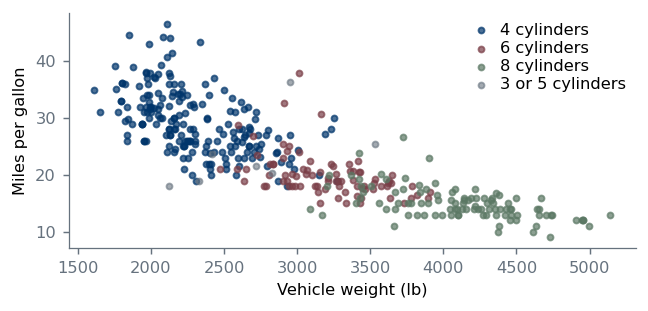

In [4]:
auto_hidden_groups()

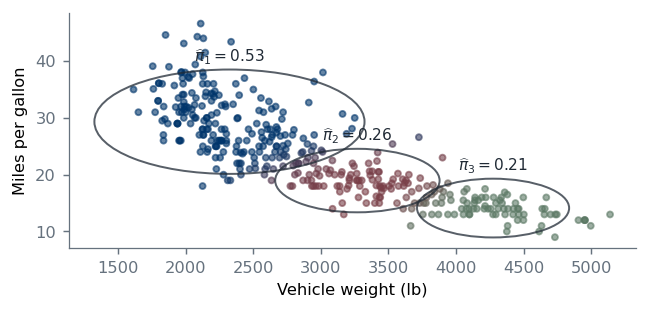

In [5]:
auto_mixture()

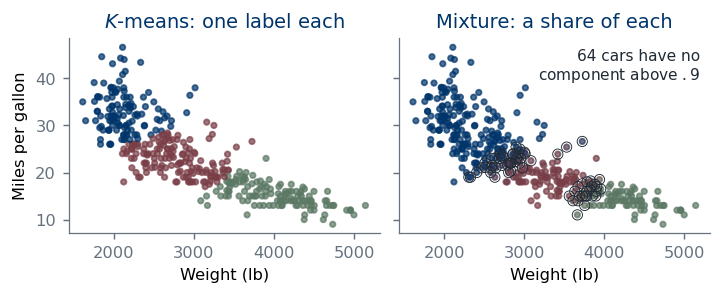

In [6]:
auto_hard_versus_soft()

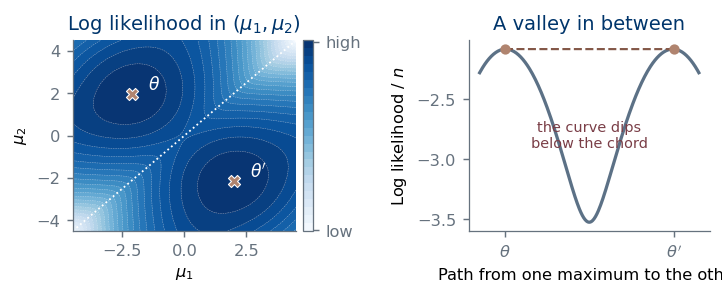

In [7]:
likelihood_landscape()

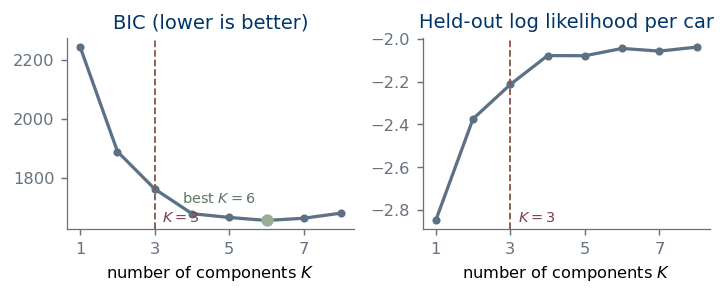

K: [1, 2, 3, 4, 5, 6, 7, 8]
BIC: [2242.8, 1888.7, 1761.9, 1678.3, 1665.5, 1655.3, 1663.0, 1680.3]
held-out: [-2.849, -2.374, -2.213, -2.078, -2.078, -2.044, -2.057, -2.038]
min N_k: [392.0, 158.5, 81.6, 77.2, 24.3, 24.7, 21.3, 13.6]


In [8]:
choosing_k()

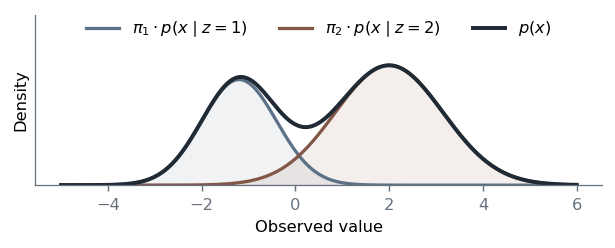

In [9]:
mixture_density()

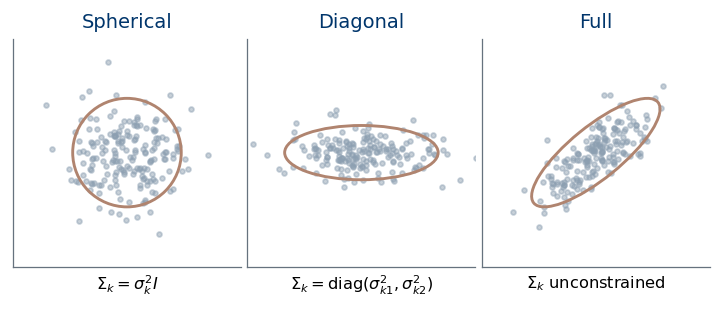

In [10]:
covariance_geometry()

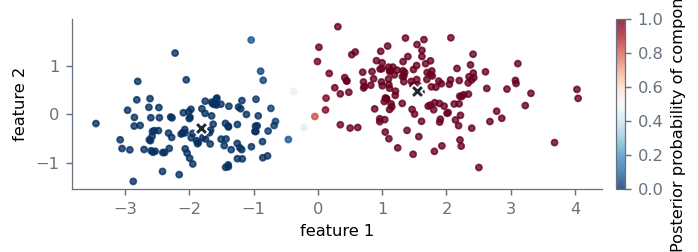

In [11]:
responsibilities()

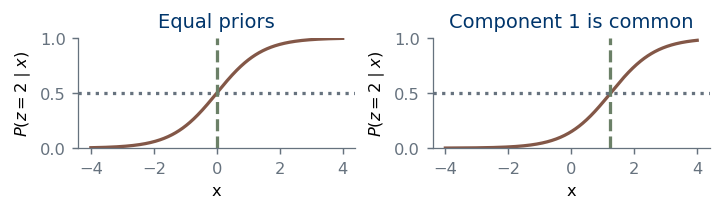

In [12]:
prior_effect()

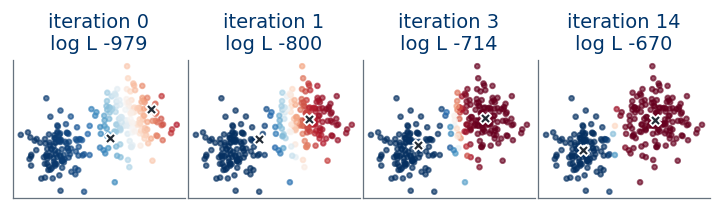

In [13]:
em_iterations()

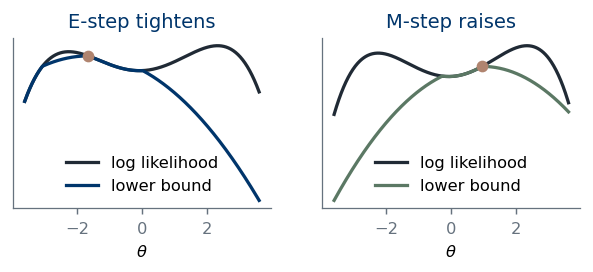

In [14]:
bound_picture()

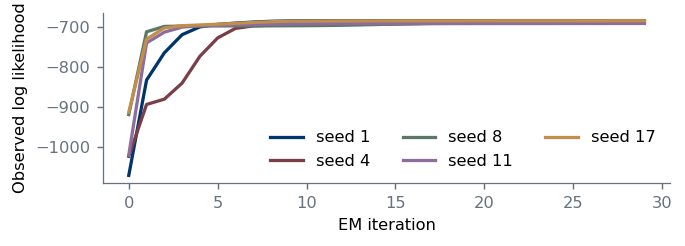

In [15]:
restarts()

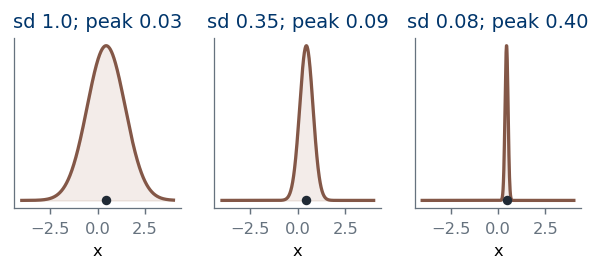

In [16]:
collapse()